Best Val Log-Loss: 0.27253
Test Brier Score:  0.07262  (StatsBomb xG: 0.07230)
Test Log-Loss:     0.25629  (StatsBomb xG: 0.25598)
Test ROC-AUC:      0.81042  (StatsBomb xG: 0.81352)


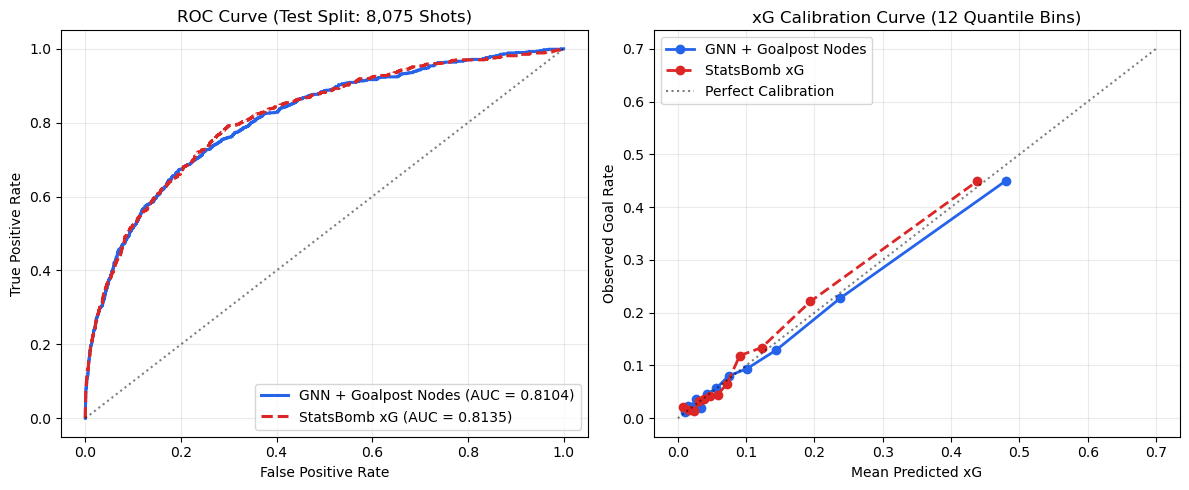

In [2]:
import gc
import time
import zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score, roc_curve
from sklearn.calibration import calibration_curve

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ==============================================================================
# 1. GEOMETRIC HELPERS: EXACT POINT-TO-SEGMENT CLEARANCES & VIRTUAL POST NODES
# ==============================================================================
def point_to_segment_stats(px, py, ax, ay, bx, by):
    """
    Computes exact Euclidean distance and clamped projection parameter t in [0, 1]
    from point P(px, py) to line segment AB from A(ax, ay) to B(bx, by).
    """
    vx, vy = bx - ax, by - ay
    ux, uy = px - ax, py - ay
    seg_len_sq = np.maximum(vx * vx + vy * vy, 1e-8)
    t = np.clip((ux * vx + uy * vy) / seg_len_sq, 0.0, 1.0)
    proj_x, proj_y = ax + t * vx, ay + t * vy
    dist = np.sqrt((px - proj_x) ** 2 + (py - proj_y) ** 2)
    return dist, t, proj_x, proj_y


def build_virtual_goalpost_nodes(shots: pd.DataFrame, post_y: float, is_left: bool) -> pd.DataFrame:
    """Creates static virtual Goalpost nodes at (120, 36) [Left] and (120, 44) [Right]."""
    n_shots = len(shots)
    sx, sy = shots["location_x"].values, shots["location_y"].values
    dx_p, dy_p = 120.0 - sx, post_y - sy
    dist_sh_p = np.sqrt(dx_p ** 2 + dy_p ** 2)
    ang_sh_p = np.arctan2(dy_p, dx_p)

    # Perpendicular distance of post (120, post_y) to shot-center ray S -> (120, 40)
    gx, gy = 120.0 - sx, 40.0 - sy
    g_len = np.maximum(np.sqrt(gx ** 2 + gy ** 2), 1e-6)
    dsl_p = np.abs(dx_p * gy - dy_p * gx) / g_len

    return pd.DataFrame({
        "graph_idx": shots["graph_idx"].values,
        "node_idx": np.full(n_shots, 1000 if is_left else 1001, dtype=np.int32),
        "position_group": ["POST"] * n_shots,
        "x": np.full(n_shots, 120.0, dtype=np.float32),
        "y": np.full(n_shots, post_y, dtype=np.float32),
        "dx": dx_p.astype(np.float32),
        "dy": dy_p.astype(np.float32),
        "dist_goal": np.full(n_shots, 4.0, dtype=np.float32),
        "angle_goal": np.zeros(n_shots, dtype=np.float32),
        "dist_shooter": dist_sh_p.astype(np.float32),
        "dist_to_shot_line": dsl_p.astype(np.float32),
        "angle_shooter_sin": np.sin(ang_sh_p).astype(np.float32),
        "angle_shooter_cos": np.cos(ang_sh_p).astype(np.float32),
        "teammate": np.zeros(n_shots, dtype=np.int8),
        "is_keeper": np.zeros(n_shots, dtype=np.int8),
        "is_shooter": np.zeros(n_shots, dtype=np.int8),
        "in_shot_triangle": np.ones(n_shots, dtype=np.int8),
        "d_seg_left": np.full(n_shots, 0.0 if is_left else 8.0, dtype=np.float32),
        "d_seg_right": np.full(n_shots, 8.0 if is_left else 0.0, dtype=np.float32),
        "d_seg_goalline": np.zeros(n_shots, dtype=np.float32),
        "t_seg_left": np.full(n_shots, 1.0 if is_left else 0.0, dtype=np.float32),
        "t_seg_right": np.full(n_shots, 0.0 if is_left else 1.0, dtype=np.float32),
        "d_left_post": np.full(n_shots, 0.0 if is_left else 8.0, dtype=np.float32),
        "d_right_post": np.full(n_shots, 8.0 if is_left else 0.0, dtype=np.float32),
        "signed_cone_clearance": np.zeros(n_shots, dtype=np.float32),
        "rel_cone_pos": np.full(n_shots, 0.0 if is_left else 1.0, dtype=np.float32),
        "occ_fraction": np.zeros(n_shots, dtype=np.float32),
        "in_back_4": np.zeros(n_shots, dtype=np.float32),
        "in_front_7": np.zeros(n_shots, dtype=np.float32),
        "in_cone_flag": np.ones(n_shots, dtype=np.float32),
        "is_left_post": np.full(n_shots, 1.0 if is_left else 0.0, dtype=np.float32),
        "is_right_post": np.full(n_shots, 0.0 if is_left else 1.0, dtype=np.float32),
    })


# ==============================================================================
# 2. LOAD DATASET & BUILD GRAPH TENSORS
# ==============================================================================
def prepare_graph_data(shot_csv="shot_table.csv", player_zip="ezyZip.zip"):
    shots = pd.read_csv(shot_csv).reset_index(drop=True)
    n_shots = len(shots)
    shots["graph_idx"] = np.arange(n_shots, dtype=np.int32)
    shot_id_to_idx = dict(zip(shots["shot_id"], shots["graph_idx"]))

    use_cols = [
        "shot_id", "node_idx", "position_group", "x", "y", "dx", "dy",
        "dist_goal", "angle_goal", "dist_shooter", "dist_to_shot_line",
        "angle_shooter_sin", "angle_shooter_cos",
        "teammate", "is_keeper", "is_shooter", "in_shot_triangle"
    ]
    with zipfile.ZipFile(player_zip, "r") as z:
        with z.open("player_table.csv") as f:
            players = pd.read_csv(f, usecols=use_cols)

    players["graph_idx"] = players["shot_id"].map(shot_id_to_idx).astype(np.int32)
    players.drop(columns=["shot_id"], inplace=True)

    sx_arr = shots["location_x"].values[players["graph_idx"].values]
    sy_arr = shots["location_y"].values[players["graph_idx"].values]
    s_ang_arr = shots["angle_goal"].values[players["graph_idx"].values]
    px, py = players["x"].values, players["y"].values

    # Exact lateral clearances to Left Post segment S->(120,36), Right Post segment S->(120,44), and Goal Line
    d_seg_left, t_seg_left, _, _ = point_to_segment_stats(px, py, sx_arr, sy_arr, 120.0, 36.0)
    d_seg_right, t_seg_right, _, _ = point_to_segment_stats(px, py, sx_arr, sy_arr, 120.0, 44.0)
    d_seg_goalline, _, _, _ = point_to_segment_stats(px, py, 120.0, 36.0, 120.0, 44.0)

    d_left_post = np.sqrt((120.0 - px) ** 2 + (36.0 - py) ** 2)
    d_right_post = np.sqrt((120.0 - px) ** 2 + (44.0 - py) ** 2)

    # Signed lateral clearance to cone boundary (+ inside cone, - outside cone)
    min_ray_dist = np.minimum(d_seg_left, d_seg_right)
    in_tri = players["in_shot_triangle"].values == 1
    is_sh_raw = players["is_shooter"].values == 1
    signed_cone_clearance = np.where(is_sh_raw, 0.0, np.where(in_tri, min_ray_dist, -min_ray_dist))

    # Normalized lateral angle fraction across cone [0 = left post ray, 1 = right post ray]
    ang_left_ray = np.arctan2(36.0 - sy_arr, 120.0 - sx_arr)
    ang_right_ray = np.arctan2(44.0 - sy_arr, 120.0 - sx_arr)
    ang_player = np.arctan2(py - sy_arr, px - sx_arr)
    cone_span = np.maximum(ang_right_ray - ang_left_ray, 1e-5)
    rel_cone_pos = np.where(is_sh_raw, 0.5, np.clip((ang_player - ang_left_ray) / cone_span, -0.5, 1.5))

    # Angular shadow blocked by player's body (~0.45 yd radius) relative to visible goal angle
    body_occ_angle = np.where(is_sh_raw, 0.0, 2.0 * np.arctan(0.45 / np.maximum(players["dist_shooter"].values, 0.5)))
    occ_fraction = np.where(in_tri, np.minimum(1.0, body_occ_angle / np.maximum(s_ang_arr, 1e-3)), 0.0)

    # Zone filtering: Shooter U 4y back semicircle U 7y front semicircle U cone U goalkeeper
    in_back_4 = (~is_sh_raw) & (players["dx"].values < 0) & (players["dist_shooter"].values <= 4.0)
    in_front_7 = (~is_sh_raw) & (players["dx"].values >= 0) & (players["dist_shooter"].values <= 7.0)
    in_cone = (~is_sh_raw) & in_tri
    is_gk = players["is_keeper"].values == 1

    keep_mask = is_sh_raw | in_back_4 | in_front_7 | in_cone | is_gk
    active = players[keep_mask].copy()

    active["d_seg_left"] = d_seg_left[keep_mask].astype(np.float32)
    active["d_seg_right"] = d_seg_right[keep_mask].astype(np.float32)
    active["d_seg_goalline"] = d_seg_goalline[keep_mask].astype(np.float32)
    active["t_seg_left"] = t_seg_left[keep_mask].astype(np.float32)
    active["t_seg_right"] = t_seg_right[keep_mask].astype(np.float32)
    active["d_left_post"] = d_left_post[keep_mask].astype(np.float32)
    active["d_right_post"] = d_right_post[keep_mask].astype(np.float32)
    active["signed_cone_clearance"] = signed_cone_clearance[keep_mask].astype(np.float32)
    active["rel_cone_pos"] = rel_cone_pos[keep_mask].astype(np.float32)
    active["occ_fraction"] = occ_fraction[keep_mask].astype(np.float32)
    active["in_back_4"] = in_back_4[keep_mask].astype(np.float32)
    active["in_front_7"] = in_front_7[keep_mask].astype(np.float32)
    active["in_cone_flag"] = in_cone[keep_mask].astype(np.float32)
    active["is_left_post"] = np.float32(0.0)
    active["is_right_post"] = np.float32(0.0)

    del players
    gc.collect()

    # Append 2 virtual Goalpost nodes per shot and sort so node 0 per graph is always the Shooter
    full_nodes = pd.concat(
        [active, build_virtual_goalpost_nodes(shots, 36.0, True), build_virtual_goalpost_nodes(shots, 44.0, False)],
        ignore_index=True,
    )
    full_nodes = full_nodes.sort_values(
        ["graph_idx", "is_shooter", "node_idx"], ascending=[True, False, True]
    ).reset_index(drop=True)

    # Standardize continuous node features using train split statistics only
    train_graph_set = set(np.where(shots["split"].values == "train")[0])
    is_train_node = full_nodes["graph_idx"].isin(train_graph_set).values

    cont_cols = [
        "x", "y", "dx", "dy", "dist_goal", "angle_goal", "dist_shooter", "dist_to_shot_line",
        "d_seg_left", "d_seg_right", "d_seg_goalline", "d_left_post", "d_right_post",
        "signed_cone_clearance"
    ]
    norm_node_cols = []
    for c in cont_cols:
        vals = full_nodes[c].values.astype(np.float32)
        mu, sd = vals[is_train_node].mean(), max(vals[is_train_node].std(), 1e-6)
        full_nodes[c + "_z"] = ((vals - mu) / sd).astype(np.float32)
        norm_node_cols.append(c + "_z")

    pos_dummies = pd.get_dummies(full_nodes["position_group"], prefix="pos", dtype=np.float32)
    extra_node_cols = [
        "angle_shooter_sin", "angle_shooter_cos", "t_seg_left", "t_seg_right",
        "rel_cone_pos", "occ_fraction",
        "teammate", "is_keeper", "is_shooter", "in_shot_triangle",
        "in_back_4", "in_front_7", "in_cone_flag", "is_left_post", "is_right_post"
    ]
    X_node_all = np.hstack([
        full_nodes[norm_node_cols].values.astype(np.float32),
        full_nodes[extra_node_cols].values.astype(np.float32),
        pos_dummies.values
    ]).astype(np.float32)

    shot_feat_cols = [
        "location_x_z", "location_y_z", "dist_goal_z", "angle_goal_z",
        "first_time", "under_pressure",
        "shot_type_Free_Kick", "shot_type_Open_Play", "shot_type_Other",
        "body_part_Head", "body_part_Left_Foot", "body_part_Other", "body_part_Right_Foot",
        "technique_Backheel", "technique_Diving_Header", "technique_Half_Volley",
        "technique_Lob", "technique_Normal", "technique_Overhead_Kick", "technique_Volley",
        "play_pattern_From_Corner", "play_pattern_From_Counter", "play_pattern_From_Free_Kick",
        "play_pattern_From_Goal_Kick", "play_pattern_From_Keeper", "play_pattern_From_Kick_Off",
        "play_pattern_From_Throw_In", "play_pattern_Other", "play_pattern_Regular_Play"
    ]
    X_shot_all = shots[shot_feat_cols].values.astype(np.float32)
    y_all = shots["is_goal"].values.astype(np.float32)
    sb_xg_all = shots["statsbomb_xg"].values.astype(np.float64)
    splits = shots["split"].values

    # Generate directed edges within each shot graph
    g_idx = full_nodes["graph_idx"].values
    counts = np.bincount(g_idx, minlength=n_shots)
    offsets = np.zeros(n_shots + 1, dtype=np.int32)
    offsets[1:] = np.cumsum(counts)

    src_list, dst_list, graph_list = [], [], []
    for k in range(2, counts.max() + 1):
        g_k = np.where(counts == k)[0]
        if len(g_k) == 0:
            continue
        base = offsets[g_k][:, None]
        r, c = np.where(~np.eye(k, dtype=bool))
        src_list.append((base + r[None, :]).ravel())
        dst_list.append((base + c[None, :]).ravel())
        graph_list.append(np.repeat(g_k, len(r)))

    src_all = np.concatenate(src_list)
    dst_all = np.concatenate(dst_list)
    edge_graph_all = np.concatenate(graph_list)
    sort_e = np.argsort(edge_graph_all, kind="mergesort")
    src_all, dst_all, edge_graph_all = src_all[sort_e], dst_all[sort_e], edge_graph_all[sort_e]

    nx, ny = full_nodes["x"].values, full_nodes["y"].values
    n_dg, n_dsl = full_nodes["dist_goal"].values, full_nodes["dist_to_shot_line"].values
    n_tm = full_nodes["teammate"].values
    n_gk = full_nodes["is_keeper"].values == 1
    n_sh = full_nodes["is_shooter"].values == 1
    n_lp = full_nodes["is_left_post"].values == 1
    n_rp = full_nodes["is_right_post"].values == 1
    n_post = n_lp | n_rp
    n_b4, n_f7 = full_nodes["in_back_4"].values, full_nodes["in_front_7"].values
    n_cn = full_nodes["in_cone_flag"].values == 1
    n_clr = full_nodes["signed_cone_clearance"].values
    n_dsl_l, n_dsl_r = full_nodes["d_seg_left"].values, full_nodes["d_seg_right"].values
    n_occ = full_nodes["occ_fraction"].values

    dx_pair = nx[dst_all] - nx[src_all]
    dy_pair = ny[dst_all] - ny[src_all]
    dist_pair = np.sqrt(dx_pair ** 2 + dy_pair ** 2)

    src_sh, dst_sh = n_sh[src_all], n_sh[dst_all]
    src_post, dst_post = n_post[src_all], n_post[dst_all]
    src_cone_or_gk = n_cn[src_all] | n_gk[src_all]
    dst_cone_or_gk = n_cn[dst_all] | n_gk[dst_all]

    # Active edge mask:
    # 1. Shooter <-> Active Zone Players
    # 2. Shooter <-> Both Virtual Goalpost Nodes (cone boundary rays)
    # 3. Left Post <-> Right Post (8-yard goal mouth)
    # 4. Cone Players & Goalkeeper <-> Both Virtual Goalpost Nodes
    # 5. Local Non-Shooter proximity edges (<= 5.0 yds)
    is_sh_player = (src_sh & (~dst_post)) | (dst_sh & (~src_post))
    is_sh_post = (src_sh & dst_post) | (dst_sh & src_post)
    is_post_post = src_post & dst_post
    is_cone_player_post = (
        (src_cone_or_gk & (~src_sh) & (~src_post) & dst_post)
        | (dst_cone_or_gk & (~dst_sh) & (~dst_post) & src_post)
    )
    is_player_player = (~src_sh) & (~dst_sh) & (~src_post) & (~dst_post) & (dist_pair <= 5.0)

    edge_keep = is_sh_player | is_sh_post | is_post_post | is_cone_player_post | is_player_player
    src_all, dst_all, edge_graph_all = src_all[edge_keep], dst_all[edge_keep], edge_graph_all[edge_keep]
    dx_pair, dy_pair, dist_pair = dx_pair[edge_keep], dy_pair[edge_keep], dist_pair[edge_keep]
    inv_dist = 1.0 / (1.0 + dist_pair)
    ddist_goal = n_dg[dst_all] - n_dg[src_all]

    is_sh_player = is_sh_player[edge_keep]
    is_sh_post = is_sh_post[edge_keep]
    is_post_post = is_post_post[edge_keep]
    is_cone_player_post = is_cone_player_post[edge_keep]
    src_sh, dst_sh = n_sh[src_all], n_sh[dst_all]
    src_post, dst_post = n_post[src_all], n_post[dst_all]

    # 8 semantic edge types
    rel_type = np.full(len(src_all), 7, dtype=np.int64)
    other_tm = np.where(src_sh, n_tm[dst_all], n_tm[src_all])
    other_gk = np.where(src_sh, n_gk[dst_all], n_gk[src_all])
    rel_type[is_sh_player & other_gk] = 2
    rel_type[is_sh_player & (~other_gk) & (other_tm == 1)] = 1
    rel_type[is_sh_player & (~other_gk) & (other_tm == 0)] = 0
    rel_type[is_sh_post] = 3
    player_side_gk = np.where(dst_post, n_gk[src_all], n_gk[dst_all])
    rel_type[is_cone_player_post & player_side_gk] = 4
    rel_type[is_cone_player_post & (~player_side_gk)] = 5
    rel_type[is_post_post] = 6

    rel_onehot = np.eye(8, dtype=np.float32)[rel_type]
    edge_clearance = np.where(src_sh | src_post, n_clr[dst_all], n_clr[src_all]) / 5.0
    edge_ray_dist = np.where(
        n_lp[src_all] | n_lp[dst_all],
        np.where(n_lp[src_all], n_dsl_l[dst_all], n_dsl_l[src_all]),
        np.where(
            n_rp[src_all] | n_rp[dst_all],
            np.where(n_rp[src_all], n_dsl_r[dst_all], n_dsl_r[src_all]),
            np.minimum(n_dsl_l[dst_all], n_dsl_r[dst_all]),
        ),
    ) / 5.0
    edge_occ = np.maximum(n_occ[src_all], n_occ[dst_all])

    E_all = np.column_stack([
        dist_pair / 10.0, inv_dist, dx_pair / 10.0, dy_pair / 10.0,
        ddist_goal / 10.0, n_dsl[dst_all] / 10.0,
        edge_clearance, edge_ray_dist, edge_occ,
        np.maximum(n_b4[src_all], n_b4[dst_all]),
        np.maximum(n_f7[src_all], n_f7[dst_all]),
        np.maximum(n_cn[src_all].astype(np.float32), n_cn[dst_all].astype(np.float32)),
        rel_onehot,
    ]).astype(np.float32)

    return {
        "shots": shots, "full_nodes": full_nodes,
        "X_node": X_node_all, "X_shot": X_shot_all, "y": y_all, "sb_xg": sb_xg_all,
        "splits": splits, "counts": counts, "offsets": offsets,
        "src": src_all, "dst": dst_all, "edge_graph": edge_graph_all, "E": E_all,
    }


# ==============================================================================
# 3. SHOT-CONDITIONED EDGE-ATTENTION GNN MODEL
# ==============================================================================
class ShotConditionedGNNLayer(nn.Module):
    def __init__(self, hidden_dim: int, edge_dim: int, dropout: float = 0.15):
        super().__init__()
        in_dim = hidden_dim * 2 + edge_dim + hidden_dim
        self.msg_mlp = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
        )
        self.gate_mlp = nn.Sequential(
            nn.Linear(in_dim, hidden_dim // 2),
            nn.SiLU(),
            nn.Linear(hidden_dim // 2, 1),
            nn.Sigmoid(),
        )
        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, h, src, dst, e_attr, e_graph, shot_ctx):
        edge_in = torch.cat([h[src], h[dst], e_attr, shot_ctx[e_graph]], dim=-1)
        msg = self.msg_mlp(edge_in) * self.gate_mlp(edge_in)
        agg = torch.zeros_like(h)
        agg.index_add_(0, dst, msg)
        deg = torch.zeros(h.size(0), device=h.device)
        deg.index_add_(0, dst, torch.ones(dst.size(0), device=h.device))
        agg = agg / torch.sqrt(deg.clamp(min=1.0)).unsqueeze(-1)
        return self.norm(h + agg)


class GoalpostShotXG_GNN(nn.Module):
    def __init__(self, node_dim: int, edge_dim: int, shot_dim: int, hidden_dim: int = 64, dropout: float = 0.15):
        super().__init__()
        self.node_enc = nn.Sequential(nn.Linear(node_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.SiLU())
        self.shot_enc = nn.Sequential(
            nn.Linear(shot_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.SiLU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.SiLU(),
        )
        self.layer1 = ShotConditionedGNNLayer(hidden_dim, edge_dim, dropout)
        self.layer2 = ShotConditionedGNNLayer(hidden_dim, edge_dim, dropout)
        self.pool_attn = nn.Linear(hidden_dim, 1)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 3, hidden_dim), nn.LayerNorm(hidden_dim), nn.SiLU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, 1),
        )

    def forward(self, x_node, node_batch, shooter_idx, src, dst, e_attr, e_graph, x_shot):
        h = self.node_enc(x_node)
        c = self.shot_enc(x_shot)
        h = self.layer1(h, src, dst, e_attr, e_graph, c)
        h = self.layer2(h, src, dst, e_attr, e_graph, c)

        h_shooter = h[shooter_idx]
        scores = self.pool_attn(h).squeeze(-1)
        max_s = torch.full((c.size(0),), -1e9, device=h.device)
        max_s.scatter_reduce_(0, node_batch, scores, reduce="amax", include_self=True)
        w = torch.exp(scores - max_s[node_batch])
        denom = torch.zeros(c.size(0), device=h.device).index_add_(0, node_batch, w)
        alpha = (w / denom[node_batch].clamp(min=1e-8)).unsqueeze(-1)
        h_pool = torch.zeros_like(c).index_add_(0, node_batch, alpha * h)

        return self.head(torch.cat([h_shooter, h_pool, c], dim=-1)).squeeze(-1)


# ==============================================================================
# 4. BATCHING, TRAINING & BENCHMARKING AGAINST STATSBOMB XG
# ==============================================================================
def build_split_batches(data, graph_indices, batch_size=1024, shuffle=False):
    if shuffle:
        graph_indices = np.random.permutation(graph_indices)
    n_shots = len(data["shots"])
    e_counts = np.bincount(data["edge_graph"], minlength=n_shots)
    e_offsets = np.zeros(n_shots + 1, dtype=np.int32)
    e_offsets[1:] = np.cumsum(e_counts)

    batches = []
    for start in range(0, len(graph_indices), batch_size):
        g_batch = graph_indices[start : start + batch_size]
        B = len(g_batch)
        n_cnts = data["counts"][g_batch]
        n_starts = data["offsets"][g_batch]
        total_nodes = int(n_cnts.sum())

        node_slices = np.concatenate([np.arange(s, s + c) for s, c in zip(n_starts, n_cnts)])
        node_batch_id = np.repeat(np.arange(B, dtype=np.int64), n_cnts)
        shooter_local_idx = np.zeros(B, dtype=np.int64)
        shooter_local_idx[1:] = np.cumsum(n_cnts[:-1])

        global_to_local = np.empty(len(data["X_node"]), dtype=np.int64)
        global_to_local[node_slices] = np.arange(total_nodes, dtype=np.int64)

        ec = e_counts[g_batch]
        es = e_offsets[g_batch]
        edge_slices = np.concatenate([np.arange(s, s + c) for s, c in zip(es, ec) if c > 0])

        batches.append((
            torch.from_numpy(data["X_node"][node_slices]).to(device),
            torch.from_numpy(node_batch_id).to(device),
            torch.from_numpy(shooter_local_idx).to(device),
            torch.from_numpy(global_to_local[data["src"][edge_slices]]).to(device),
            torch.from_numpy(global_to_local[data["dst"][edge_slices]]).to(device),
            torch.from_numpy(data["E"][edge_slices]).to(device),
            torch.from_numpy(np.repeat(np.arange(B, dtype=np.int64), ec)).to(device),
            torch.from_numpy(data["X_shot"][g_batch]).to(device),
            torch.from_numpy(data["y"][g_batch]).to(device),
        ))
    return batches


if __name__ == "__main__":
    data = prepare_graph_data("shot_table.csv", "ezyZip.zip")
    train_idx = np.where(data["splits"] == "train")[0]
    val_idx = np.where(data["splits"] == "val")[0]
    test_idx = np.where(data["splits"] == "test")[0]

    val_batches = build_split_batches(data, val_idx, batch_size=1024, shuffle=False)
    test_batches = build_split_batches(data, test_idx, batch_size=1024, shuffle=False)

    epochs = 16
    model = GoalpostShotXG_GNN(
        node_dim=data["X_node"].shape[1],
        edge_dim=data["E"].shape[1],
        shot_dim=data["X_shot"].shape[1],
        hidden_dim=64,
        dropout=0.15,
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.BCEWithLogitsLoss()

    best_val_loss, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        model.train()
        for batch in build_split_batches(data, train_idx, batch_size=1024, shuffle=True):
            x_n, nb, s_idx, src, dst, ea, eg, x_s, y = batch
            optimizer.zero_grad()
            loss = criterion(model(x_n, nb, s_idx, src, dst, ea, eg, x_s), y)
            loss.backward()
            optimizer.step()
        scheduler.step()

        model.eval()
        vp, vt = [], []
        with torch.no_grad():
            for batch in val_batches:
                x_n, nb, s_idx, src, dst, ea, eg, x_s, y = batch
                vp.append(torch.sigmoid(model(x_n, nb, s_idx, src, dst, ea, eg, x_s)).cpu().numpy())
                vt.append(y.cpu().numpy())
        v_ll = log_loss(np.concatenate(vt), np.clip(np.concatenate(vp), 1e-6, 1 - 1e-6))
        if v_ll < best_val_loss:
            best_val_loss = v_ll
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.eval()
    tp, tt = [], []
    with torch.no_grad():
        for batch in test_batches:
            x_n, nb, s_idx, src, dst, ea, eg, x_s, y = batch
            tp.append(torch.sigmoid(model(x_n, nb, s_idx, src, dst, ea, eg, x_s)).cpu().numpy())
            tt.append(y.cpu().numpy())

    preds_gp = np.concatenate(tp).astype(np.float64)
    y_test = np.concatenate(tt).astype(np.float64)
    sb_test = np.clip(data["sb_xg"][test_idx], 1e-6, 1 - 1e-6)

    print(f"Best Val Log-Loss: {best_val_loss:.5f}")
    print(f"Test Brier Score:  {brier_score_loss(y_test, preds_gp):.5f}  (StatsBomb xG: {brier_score_loss(y_test, sb_test):.5f})")
    print(f"Test Log-Loss:     {log_loss(y_test, np.clip(preds_gp, 1e-6, 1 - 1e-6)):.5f}  (StatsBomb xG: {log_loss(y_test, sb_test):.5f})")
    print(f"Test ROC-AUC:      {roc_auc_score(y_test, preds_gp):.5f}  (StatsBomb xG: {roc_auc_score(y_test, sb_test):.5f})")

    # Plot ROC Curve & Calibration Curve vs StatsBomb xG
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for label, probs, style, col in [
        (f"GNN + Goalpost Nodes (AUC = {roc_auc_score(y_test, preds_gp):.4f})", preds_gp, "-", "#2563eb"),
        (f"StatsBomb xG (AUC = {roc_auc_score(y_test, sb_test):.4f})", sb_test, "--", "#dc2626"),
    ]:
        fpr, tpr, _ = roc_curve(y_test, probs)
        axes[0].plot(fpr, tpr, linestyle=style, color=col, linewidth=2.2, label=label)
        frac_pos, mean_pred = calibration_curve(y_test, probs, n_bins=12, strategy="quantile")
        axes[1].plot(mean_pred, frac_pos, marker="o", linestyle=style, color=col, linewidth=2, label=label.split(" (")[0])

    axes[0].plot([0, 1], [0, 1], "k:", alpha=0.5)
    axes[0].set(title="ROC Curve (Test Split: 8,075 Shots)", xlabel="False Positive Rate", ylabel="True Positive Rate")
    axes[0].grid(alpha=0.25)
    axes[0].legend(loc="lower right")

    axes[1].plot([0, 0.7], [0, 0.7], "k:", alpha=0.5, label="Perfect Calibration")
    axes[1].set(title="xG Calibration Curve (12 Quantile Bins)", xlabel="Mean Predicted xG", ylabel="Observed Goal Rate")
    axes[1].grid(alpha=0.25)
    axes[1].legend(loc="upper left")

    plt.tight_layout()
    plt.savefig("gnn_goalpost_vs_statsbomb.png", dpi=200)
    torch.save(best_state, "goalpost_xg_gnn.pt")